# Moosic 02: How many playlists? (choosing k)

**Goal of this notebook:** find the number of clusters (playlists) that fits the business rule.

**Business rule:** every playlist must have **50 to 250 songs**. With about 5,000 songs, that means between
5,000 / 250 = **20** and 5,000 / 50 = **100** playlists. So we test every k from 20 to 100.

We use three checks:
1. **Inertia (elbow method):** how tight the playlists are. Lower is better, but it always goes down when k grows,
   so we look for a bend ("elbow").
2. **Silhouette score:** how clearly each song belongs to its own playlist rather than the next one (-1 to 1, higher is better).
3. **Playlist sizes:** does every playlist have 50 to 250 songs?

**Input:** `data/songs_clean.csv` (made by notebook 01)

## 1. Load the clean data

In [1]:
import pandas as pd

In [2]:
songs_df = pd.read_csv('../data/songs_clean.csv')

In [3]:
# name + artist as the index, so we always know which song a row is
songs_df = songs_df.set_index(['name', 'artist'])

In [4]:
print(len(songs_df), 'songs')

5114 songs


In [5]:
songs_df.describe()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
count,5114.000000,5114.000000,5114.000000,5114.000000,5114.000000,5114.000000,5114.000000,5114.000000,5114.000000,5114.000000,5114.000000,5.114000e+03,5114.000000
mean,0.506326,0.653259,5.265546,-9.393082,0.648221,0.082974,0.291699,0.261329,0.185562,0.440924,118.635675,2.485728e+05,3.901251
std,0.218045,0.289923,3.571389,6.316429,0.477572,0.070686,0.357064,0.372177,0.149882,0.277684,28.634131,1.369418e+05,0.421673
min,0.000000,0.000000,0.000000,-60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.276000e+04,0.000000
25%,0.304000,0.475000,2.000000,-11.390750,0.000000,0.038900,0.002210,0.000001,0.092500,0.194250,96.058250,1.896998e+05,4.000000
50%,0.534000,0.738000,5.000000,-7.372000,1.000000,0.055400,0.096400,0.002360,0.125000,0.412500,118.987500,2.252800e+05,4.000000
75%,0.684000,0.896000,8.000000,-5.318500,1.000000,0.098800,0.570750,0.659750,0.237000,0.674000,134.098000,2.721568e+05,4.000000
max,0.967000,1.000000,11.000000,1.342000,1.000000,0.918000,0.996000,0.985000,0.987000,0.985000,213.990000,3.815787e+06,5.000000


Minimum `loudness` = -60? That's the quietest value possible. Let's look at it.

In [6]:
songs_df.loc[songs_df['loudness'] == -60]

,,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
name,artist,,,,,,,,,,,,,
Shake It Off,Taylor Swift,0.0,0.0,0,-60.0,0,0.0,0.0,0.0,0.0,0.0,0.0,219000,0


Every value of this song is 0 or at its minimum: it's **missing data**, not a real song. We drop it.

In [7]:
songs_df = songs_df.loc[songs_df['loudness'] != -60]

In [8]:
songs_df.describe()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
count,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000,5.113000e+03,5113.000000
mean,0.506425,0.653386,5.266575,-9.383185,0.648347,0.082990,0.291756,0.261381,0.185598,0.441010,118.658878,2.485786e+05,3.902014
std,0.217951,0.289807,3.570979,6.277260,0.477533,0.070683,0.357076,0.372195,0.149874,0.277642,28.588810,1.369546e+05,0.418168
min,0.059600,0.000020,0.000000,-44.406000,0.000000,0.022600,0.000000,0.000000,0.010900,0.019600,34.856000,3.276000e+04,1.000000
25%,0.304000,0.475000,2.000000,-11.390000,0.000000,0.038900,0.002210,0.000001,0.092500,0.195000,96.059000,1.896930e+05,4.000000
50%,0.534000,0.738000,5.000000,-7.371000,1.000000,0.055400,0.096400,0.002360,0.125000,0.413000,118.988000,2.252800e+05,4.000000
75%,0.684000,0.896000,8.000000,-5.318000,1.000000,0.098800,0.571000,0.660000,0.237000,0.674000,134.099000,2.721600e+05,4.000000
max,0.967000,1.000000,11.000000,1.342000,1.000000,0.918000,0.996000,0.985000,0.987000,0.985000,213.990000,3.815787e+06,5.000000


## 2. Choose the features
We keep the **9 audio features** that describe how a song sounds, and leave out:
- `key`, `mode` and `time_signature`: categories, not amounts (key 11 isn't "more" than key 1),
- `duration_ms`: the length of a song says nothing about how it sounds.

In [9]:
audio_features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
                  'instrumentalness', 'liveness', 'valence', 'tempo']
features_df = songs_df[audio_features]

In [10]:
features_df.describe()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000,5113.000000
mean,0.506425,0.653386,-9.383185,0.082990,0.291756,0.261381,0.185598,0.441010,118.658878
std,0.217951,0.289807,6.277260,0.070683,0.357076,0.372195,0.149874,0.277642,28.588810
min,0.059600,0.000020,-44.406000,0.022600,0.000000,0.000000,0.010900,0.019600,34.856000
25%,0.304000,0.475000,-11.390000,0.038900,0.002210,0.000001,0.092500,0.195000,96.059000
50%,0.534000,0.738000,-7.371000,0.055400,0.096400,0.002360,0.125000,0.413000,118.988000
75%,0.684000,0.896000,-5.318000,0.098800,0.571000,0.660000,0.237000,0.674000,134.099000
max,0.967000,1.000000,1.342000,0.918000,0.996000,0.985000,0.987000,0.985000,213.990000


## 3. Scale the data
From notebook 01, the two most promising options are **MinMax** (the course default) and **PowerTransformer**.
We try both and compare.

In [11]:
from sklearn.preprocessing import MinMaxScaler, PowerTransformer
from sklearn import set_config
set_config(transform_output='pandas')   # scalers return DataFrames (with column names) instead of arrays

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [12]:
my_min_max = MinMaxScaler()
my_power = PowerTransformer()

minmax_df = my_min_max.fit_transform(features_df)
power_df = my_power.fit_transform(features_df)

In [13]:
minmax_df.head()

,,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
name,artist,,,,,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,0.659467,0.258985,0.683418,0.053496,0.696787,0.000060,0.987706,0.296665,0.421584
Saudade De Bahia,Antônio Carlos Jobim,0.752039,0.398988,0.694238,0.013402,0.217871,0.000002,0.098453,0.697535,0.503439
"Canta Canta, Minha Gente",Martinho Da Vila,0.872162,0.729995,0.729168,0.362296,0.454819,0.000064,0.115869,0.917133,0.328480
Mulher Eu Sei,Chico César,0.711263,0.050181,0.574692,0.027362,0.882530,0.000041,0.384284,0.522478,0.401632
Rosa Morena,Kurt Elling,0.651752,0.118982,0.537707,0.017199,0.919679,0.000348,0.095380,0.396105,0.480562


In [14]:
power_df.head()

,,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
name,artist,,,,,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,0.688660,-1.361222,-0.862465,0.206533,1.277150,-0.781932,2.074386,-0.409958,-0.209010
Saudade De Bahia,Antônio Carlos Jobim,1.086078,-1.033237,-0.796241,-1.042393,0.233410,-0.782462,-0.505131,0.931087,0.307062
"Canta Canta, Minha Gente",Martinho Da Vila,1.608326,0.099601,-0.564003,1.974728,0.906940,-0.781888,-0.256208,1.536379,-0.861172
Mulher Eu Sei,Chico César,0.910472,-1.716228,-1.418797,-0.526809,1.452406,-0.782102,1.522543,0.389273,-0.342356
Rosa Morena,Kurt Elling,0.655747,-1.615271,-1.574127,-0.892008,1.480181,-0.779282,-0.552098,-0.042144,0.167506


## 4. Test every number of playlists from 20 to 100

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

In [16]:
def inertia_calculation(df):
    """Run K-Means for every k from 20 to 100 and collect inertia, silhouette score and playlist sizes."""
    random_seed = 40                  # same seed every run, so the results don't change
    min_k, max_k = 20, 100            # range from the business rule
    nclusters, inertia, silh_score, size = [], [], [], []

    for k in range(min_k, max_k + 1):
        my_kmean = KMeans(n_clusters=k,
                          random_state=random_seed,
                          n_init='auto')
        my_kmean.fit(df)

        nclusters.append(k)
        inertia.append(my_kmean.inertia_)                             # how tight the playlists are
        silh_score.append(silhouette_score(df, my_kmean.labels_))     # how well separated they are
        size.append(np.bincount(my_kmean.labels_))                    # number of songs in each playlist

    return nclusters, inertia, silh_score, size

In [17]:
# This takes a few minutes: 81 models for each scaler
n_clusters_minmax, inertia_minmax, silhouette_minmax, size_minmax = inertia_calculation(minmax_df)
n_clusters_power, inertia_power, silhouette_power, size_power = inertia_calculation(power_df)

In [18]:
# Put the results in a table: one row per k
cluster_inertia_minmax_df = pd.DataFrame({'ncluster': n_clusters_minmax,
                                          'inertia': inertia_minmax,
                                          'silhouette': silhouette_minmax,
                                          'size': size_minmax})
cluster_inertia_minmax_df

,ncluster,inertia,silhouette,size
0,20,525.722750,0.157922,"[222, 324, 243, 493, 511, 277, 205, 181, 159, ..."
1,21,512.198632,0.151965,"[161, 206, 90, 361, 143, 214, 374, 428, 248, 3..."
2,22,501.115132,0.155027,"[160, 201, 89, 373, 128, 216, 374, 425, 63, 34..."
3,23,493.590818,0.154977,"[94, 206, 88, 316, 122, 223, 374, 403, 49, 163..."
4,24,483.472545,0.159922,"[99, 316, 88, 310, 126, 224, 181, 394, 50, 165..."
...,...,...,...,...
76,96,289.175016,0.133952,"[21, 17, 57, 18, 97, 68, 87, 57, 59, 56, 78, 6..."
77,97,287.213303,0.135186,"[22, 16, 57, 17, 97, 68, 83, 57, 54, 52, 78, 6..."
78,98,285.587301,0.136372,"[22, 16, 48, 17, 97, 68, 84, 55, 54, 52, 54, 5..."
79,99,284.624266,0.136634,"[22, 16, 51, 16, 97, 68, 84, 50, 53, 52, 54, 5..."


In [19]:
cluster_inertia_power_df = pd.DataFrame({'ncluster': n_clusters_power,
                                         'inertia': inertia_power,
                                         'silhouette': silhouette_power,
                                         'size': size_power})
cluster_inertia_power_df

,ncluster,inertia,silhouette,size
0,20,13637.094913,0.165586,"[164, 129, 306, 241, 325, 278, 308, 315, 268, ..."
1,21,13598.066054,0.160228,"[160, 126, 257, 160, 276, 166, 324, 333, 252, ..."
2,22,13406.925262,0.159298,"[162, 134, 249, 159, 279, 136, 323, 299, 244, ..."
3,23,13184.046485,0.157696,"[146, 134, 246, 164, 284, 144, 317, 306, 240, ..."
4,24,12816.266085,0.160980,"[148, 126, 257, 147, 262, 136, 228, 288, 241, ..."
...,...,...,...,...
76,96,7943.735290,0.129564,"[43, 39, 48, 34, 71, 65, 50, 152, 49, 66, 74, ..."
77,97,7931.508108,0.124511,"[43, 37, 39, 34, 73, 64, 50, 89, 49, 66, 74, 8..."
78,98,7908.219260,0.124003,"[42, 36, 39, 33, 69, 63, 47, 89, 49, 59, 74, 8..."
79,99,7871.708100,0.125060,"[42, 36, 35, 34, 67, 67, 48, 89, 46, 59, 74, 8..."


## 5. Compare both scalers

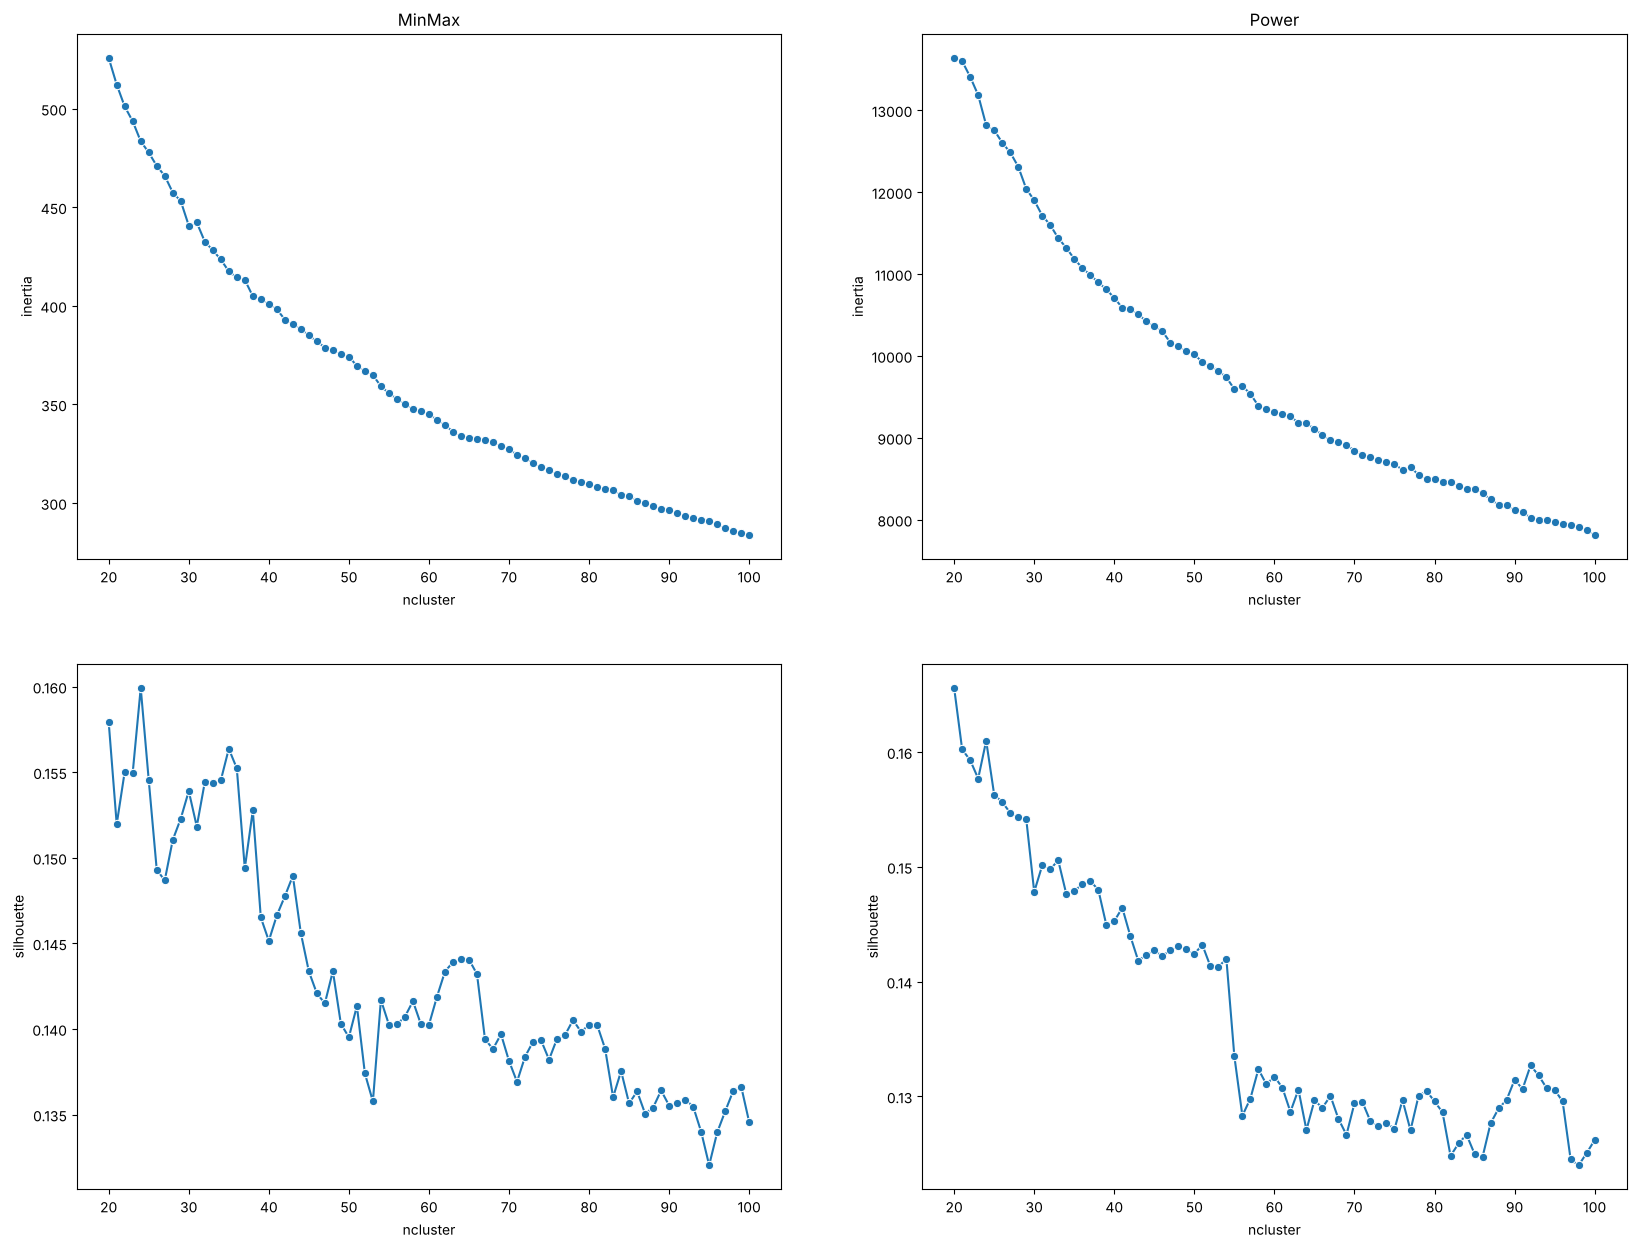

In [20]:
# Top row: inertia (elbow). Bottom row: silhouette. Left: MinMax. Right: Power.
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 15))

sns.lineplot(data=cluster_inertia_minmax_df, x='ncluster', y='inertia', marker='o', ax=ax1)
sns.lineplot(data=cluster_inertia_power_df, x='ncluster', y='inertia', marker='o', ax=ax2)
sns.lineplot(data=cluster_inertia_minmax_df, x='ncluster', y='silhouette', marker='o', ax=ax3)
sns.lineplot(data=cluster_inertia_power_df, x='ncluster', y='silhouette', marker='o', ax=ax4)

ax1.set_title('MinMax')
ax2.set_title('Power')
plt.show()

The curves change gradually: there is **no clear elbow**, and the silhouette score stays low.
Music doesn't come in naturally separate groups, so the maths alone can't pick k.
The **business rule** has to decide.

## 6. Apply the business rule: 50 to 250 songs per playlist

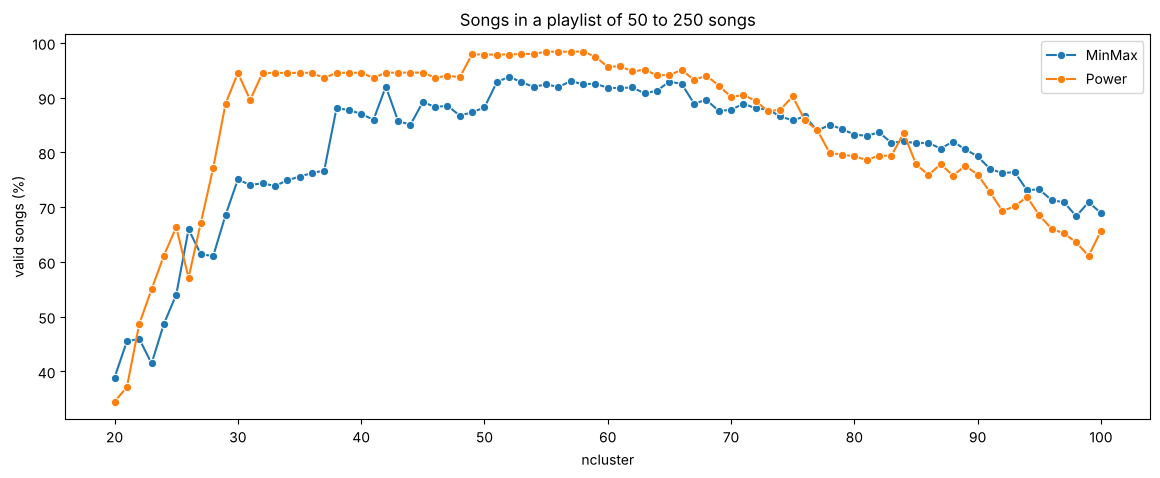

In [21]:
def share_in_valid_playlists(sizes, min_size=50, max_size=250):
    """% of songs that sit in a playlist with 50 to 250 songs."""
    valid = (sizes >= min_size) & (sizes <= max_size)
    return 100 * sizes[valid].sum() / sizes.sum()

for df in [cluster_inertia_minmax_df, cluster_inertia_power_df]:
    df['valid songs (%)'] = df['size'].apply(share_in_valid_playlists)

fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=cluster_inertia_minmax_df, x='ncluster', y='valid songs (%)', marker='o', label='MinMax', ax=ax)
sns.lineplot(data=cluster_inertia_power_df, x='ncluster', y='valid songs (%)', marker='o', label='Power', ax=ax)
ax.set_title('Songs in a playlist of 50 to 250 songs')
plt.show()

In [22]:
# For each scaler: the k values where the most songs sit in a playlist of 50-250 songs
for name, df in [('MinMax', cluster_inertia_minmax_df), ('Power', cluster_inertia_power_df)]:
    best = df.sort_values('valid songs (%)', ascending=False).head(3)
    print(name)
    print(best[['ncluster', 'valid songs (%)', 'silhouette']].round(3).to_string(index=False), '\n')

MinMax
 ncluster  valid songs (%)  silhouette
       52           93.839       0.137
       57           93.037       0.141
       65           92.940       0.144 

Power
 ncluster  valid songs (%)  silhouette
       58           98.416       0.132
       57           98.396       0.130
       56           98.396       0.128 



## 7. Conclusion
- The elbow and silhouette curves give **no clear answer**: music doesn't come in neatly separated groups.
- The **business rule** is the deciding check. In this run (without PCA, `random_state=40`), no k puts *every* song into a playlist of 50 to 250 songs,
  but **PowerTransformer comes much closer (about 98%) than MinMax (about 94%)**, so we keep PowerTransformer.
- In notebook 03 we add PCA.


**Next:** `03_pca.ipynb`, can PCA help?